# 베이스라인(XGBoost, TabPFN v3.5) vs Group-wise Cross-Attention vs 전체 데이터 한번에

| feature 세트 | 내용 |
|---|---|
| `subset` | 공선성 축소 + 그룹별 파생변수 (`src.features.build`, cross-attention 실험과 동일) |
| `full_raw` | 원본 feature 284개 전체 + 요일 (가공 없음, "전체 데이터 한번에") |
| `+exaone` | EXAONE Finance 1.0 zero-shot rolling 예측 feature 추가 (`run_exaone_feats.py`; FI·SH1·KE 80개 계열의 3일 뒤 예측 변화량과 불확실성) |

- 모델 표기는 `모델[feature 세트]`입니다. 신경망 모델은 `run_xattn.py`(subset)와 `run_xattn.py --full`(full_raw)로 실행합니다. TabPFN은 `run_tabpfn.py`로 **별도 프로세스**에서 실행합니다. XGBoost와 같은 커널에서 돌리면 libomp 충돌로 데드락이 나기 때문입니다.
- split: stratified, random, time(+3일 purge)이고 모든 모델이 같은 split을 씁니다. **stratified와 random split은 인접일 자기상관 때문에 낙관적인 점수가 나오므로, test와 가장 가까운 지표는 time split입니다.**

In [1]:
import os, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve
from xgboost import XGBClassifier
from src.data import ROOT, SCHEMES, TARGETS, group_columns, inner_split, load, make_split
from src.features import build, featsets

df, is_train = load()
groups = group_columns(df)
_, _, report = build(df, is_train, groups)
sets = featsets(df, is_train, groups)
y = df.loc[is_train, TARGETS].to_numpy().astype(int)
print({k: v.shape[1] for k, v in sets.items()})

{'subset': 255, 'full_raw': 285, 'subset+exaone': 415, 'full_raw+exaone': 445}


## 공선성 리포트 요약

In [2]:
pd.DataFrame({g: {k: v for k, v in r.items() if k != "clusters"} for g, r in report["within"].items()}).T

,n_raw,n_cluster,vif_after_cluster,n_pca,pca_var
FI,18.0,14.0,27.157639,NaN,NaN
KE,51.0,48.0,60.698434,24.0,0.894636
SH,199.0,173.0,32625.882938,22.0,0.903580
WE,15.0,12.0,73.705400,NaN,NaN


In [3]:
display(pd.DataFrame(report["cca_level"]).round(2).style.set_caption("CCA (level)"))
display(pd.DataFrame(report["cca_diff7"]).round(2).style.set_caption("CCA (7일 차분)"))
pd.DataFrame({t: {g: r["top5_mean"] for g, r in v.items()} for t, v in report["target_relevance"].items()}).round(3)

,FI,KE,SH,WE
FI,1.000000,0.880000,0.970000,0.630000
KE,0.880000,1.000000,0.920000,0.530000
SH,0.970000,0.920000,1.000000,0.910000
WE,0.630000,0.530000,0.910000,1.000000


,FI,KE,SH,WE
FI,1.000000,0.250000,0.190000,0.190000
KE,0.250000,1.000000,0.590000,0.460000
SH,0.190000,0.590000,1.000000,0.300000
WE,0.190000,0.460000,0.300000,1.000000


,Target_1,Target_2
FI,0.150,0.175
KE,0.099,0.506
SH,0.099,0.522
WE,0.070,0.072


## XGBoost (feature 세트별, seed 5개 평균, inner split early stopping)

In [4]:
SEEDS = 5
def run_xgb(X, tr, va, es, t):
    ps = []
    for s in range(SEEDS):
        m = XGBClassifier(n_estimators=1000, learning_rate=0.03, max_depth=3, subsample=0.8, colsample_bytree=0.5,
                          min_child_weight=5, reg_lambda=1.0, eval_metric="auc", early_stopping_rounds=50, random_state=s)
        m.fit(X[tr], y[tr, t], eval_set=[(X[es], y[es, t])], verbose=False)
        ps.append(m.predict_proba(X[va])[:, 1])
    return np.mean(ps, 0)

rows, preds = [], {}
for fs, F in sets.items():
    X = F[is_train].to_numpy(np.float32)
    for scheme in SCHEMES:
        tr, va = make_split(y, scheme, seed=0)
        tr_in, es = inner_split(y, tr, scheme)
        for ti, t in enumerate(TARGETS):
            p = run_xgb(X, tr_in, va, es, ti)
            preds[f"{scheme}|{t}|xgboost[{fs}]"] = {"y": y[va, ti], "p": p}
            rows.append(dict(scheme=scheme, target=t, model=f"xgboost[{fs}]", auc=roc_auc_score(y[va, ti], p)))
pd.DataFrame(rows).pivot(index=["scheme", "target"], columns="model", values="auc").round(3)

model                xgboost[full_raw+exaone]  xgboost[full_raw]  \
scheme     target                                                  
random     Target_1                     0.691              0.668   
           Target_2                     0.957              0.946   
stratified Target_1                     0.667              0.661   
           Target_2                     0.964              0.956   
time       Target_1                     0.554              0.450   
           Target_2                     0.933              0.931   

model                xgboost[subset+exaone]  xgboost[subset]  
scheme     target                                             
random     Target_1                   0.587            0.580  
           Target_2                   0.945            0.940  
stratified Target_1                   0.666            0.649  
           Target_2                   0.966            0.960  
time       Target_1                   0.476            0.558  
           Target_2                   0.934            0.908

## TabPFN v3.5 (`run_tabpfn.py` 결과 로드)

In [5]:
tp_path = ROOT / "results/tabpfn_results.json"
if tp_path.exists():
    tp = json.load(open(tp_path))
    print("TabPFN config:", tp["config"])
    for r in tp["runs"]:
        rows.append(dict(scheme=r["scheme"], target=r["target"], model=f"tabpfn[{r['featset']}]", auc=r["auc"]))
    for k, v in tp["val_preds"].items():
        preds[k] = {"y": np.array(v["y"]), "p": np.array(v["p"])}
else:
    print("results/tabpfn_results.json 없음 → `uv run python run_tabpfn.py` 먼저 실행")

TabPFN config: {'version': 'v3.5', 'device': 'mps', 'featsets': None}


## 신경망 결과 로드 (subset: cross-attention 계열, full_raw: 단일 스트림)

In [6]:
for fname, fs in [("xattn_results.json", "subset"), ("xattn_full_results.json", "full_raw")]:
    p = ROOT / "results" / fname
    if not p.exists():
        print(fname, "없음"); continue
    res = json.load(open(p))
    print(fname, "Q/KV 배정:", res["assignment"] or "단일 스트림")
    for r in res["runs"]:
        rows.append(dict(scheme=r["scheme"], target=r["target"], model=f"{r['variant']}[{fs}]", auc=r["auc_tta"]))
        if r["variant"] == "xattn":
            rows.append(dict(scheme=r["scheme"], target=r["target"], model=f"xattn_kv_shuffle[{fs}]", auc=r["auc_kv_shuffle"]))
    for k, v in res["val_preds"].items():
        s, t, var = k.split("|")
        preds[f"{s}|{t}|{var}[{fs}]"] = {"y": np.array(v["y"]), "p": np.array(v["p"])}

xattn_results.json Q/KV 배정: {'Target_1': {'Q': ['FI'], 'KV': ['KE', 'SH', 'WE']}, 'Target_2': {'Q': ['SH'], 'KV': ['FI', 'KE', 'WE']}}
xattn_full_results.json Q/KV 배정: {'Target_1': {'Q': ['ALL_RAW'], 'KV': []}, 'Target_2': {'Q': ['ALL_RAW'], 'KV': []}}


## 전체 비교표

In [7]:
comp = pd.DataFrame(rows).pivot_table(index=["scheme", "target"], columns="model", values="auc")
time_tab = comp.xs("time", level="scheme").T.sort_values("Target_1", ascending=False)
print("== time split (test와 가장 가까운 지표), Target_1 기준 정렬")
display(time_tab.round(3))
comp.T.round(3)

== time split (test와 가장 가까운 지표), Target_1 기준 정렬


target,Target_1,Target_2
model,,
tabpfn[subset+exaone],0.618,0.930
tabpfn[subset],0.590,0.941
q_only[subset],0.581,0.921
concat_mlp[subset],0.575,0.935
xgboost[subset],0.558,0.908
xgboost[full_raw+exaone],0.554,0.933
concat_mlp[full_raw],0.549,0.894
xattn[subset],0.530,0.919
tabpfn[full_raw],0.505,0.955


scheme                     random          stratified              time  \
target                   Target_1 Target_2   Target_1 Target_2 Target_1   
model                                                                     
concat_mlp[full_raw]        0.716    0.934      0.694    0.952    0.549   
concat_mlp[subset]          0.698    0.950      0.718    0.959    0.575   
q_only[full_raw]            0.740    0.946      0.740    0.948    0.482   
q_only[subset]              0.716    0.946      0.747    0.950    0.581   
tabpfn[full_raw+exaone]     0.811    0.973      0.804    0.973    0.466   
tabpfn[full_raw]            0.821    0.971      0.790    0.977    0.505   
tabpfn[subset+exaone]       0.774    0.963      0.811    0.969    0.618   
tabpfn[subset]              0.776    0.973      0.807    0.973    0.590   
xattn[subset]               0.743    0.942      0.742    0.949    0.530   
xattn_kv_shuffle[subset]    0.603    0.937      0.663    0.949    0.486   
xgboost[full_raw+exaone]    0.691    0.957      0.667    0.964    0.554   
xgboost[full_raw]           0.668    0.946      0.661    0.956    0.450   
xgboost[subset+exaone]      0.587    0.945      0.666    0.966    0.476   
xgboost[subset]             0.580    0.940      0.649    0.960    0.558   

scheme                             
target                   Target_2  
model                              
concat_mlp[full_raw]        0.894  
concat_mlp[subset]          0.935  
q_only[full_raw]            0.936  
q_only[subset]              0.921  
tabpfn[full_raw+exaone]     0.950  
tabpfn[full_raw]            0.955  
tabpfn[subset+exaone]       0.930  
tabpfn[subset]              0.941  
xattn[subset]               0.919  
xattn_kv_shuffle[subset]    0.920  
xgboost[full_raw+exaone]    0.933  
xgboost[full_raw]           0.931  
xgboost[subset+exaone]      0.934  
xgboost[subset]             0.908

### feature 세트 효과 (time split)
같은 모델 안에서 feature 세트만 바꿨을 때의 AUC입니다. 서브셋 구조, 전체 데이터, EXAONE feature 추가의 효과를 이 표로 분리해서 볼 수 있습니다.

In [8]:
t = time_tab.copy()
t["base"] = t.index.str.split("[").str[0]
t["featset"] = t.index.str.extract(r"\[(.*)\]", expand=False).values
t.pivot_table(index=["base"], columns="featset", values=TARGETS).round(3)

target           Target_1                                      Target_2  \
featset          full_raw full_raw+exaone subset subset+exaone full_raw   
base                                                                      
concat_mlp          0.549             NaN  0.575           NaN    0.894   
q_only              0.482             NaN  0.581           NaN    0.936   
tabpfn              0.505           0.466  0.590         0.618    0.955   
xattn                 NaN             NaN  0.530           NaN      NaN   
xattn_kv_shuffle      NaN             NaN  0.486           NaN      NaN   
xgboost             0.450           0.554  0.558         0.476    0.931   

target                                                 
featset          full_raw+exaone subset subset+exaone  
base                                                   
concat_mlp                   NaN  0.935           NaN  
q_only                       NaN  0.921           NaN  
tabpfn                     0.950  0.941         0.930  
xattn                        NaN  0.919           NaN  
xattn_kv_shuffle             NaN  0.920           NaN  
xgboost                    0.933  0.908         0.934

### cross-attention 진단 (subset)
- **gate**: tanh(gate) 값입니다. 0에 가까우면 cross attention이 출력에 거의 기여하지 않습니다.
- **attn_entropy**: 1이면 attention이 균등 분포입니다.
- **kv_effect**: KV를 셔플했을 때 떨어지는 AUC입니다. 0 근처면 모델이 KV를 쓰지 않습니다.

In [9]:
res = json.load(open(ROOT / "results/xattn_results.json"))
diag = pd.DataFrame([r for r in res["runs"] if r["variant"] == "xattn"])
diag = diag.assign(kv_effect=diag.auc_plain - diag.auc_kv_shuffle)
diag[["scheme", "target", "auc_plain", "auc_kv_shuffle", "kv_effect", "gate", "attn_entropy", "ffn_depth", "auc_seed_std"]].round(3)

,scheme,target,auc_plain,auc_kv_shuffle,kv_effect,gate,attn_entropy,ffn_depth,auc_seed_std
0,stratified,Target_1,0.748,0.663,0.085,0.037,0.914,2,0.016
1,stratified,Target_2,0.949,0.949,0.001,-0.015,0.971,2,0.003
2,random,Target_1,0.741,0.603,0.138,-0.099,0.913,2,0.019
3,random,Target_2,0.941,0.937,0.005,-0.038,0.944,2,0.002
4,time,Target_1,0.536,0.486,0.050,0.082,0.951,2,0.037
5,time,Target_2,0.919,0.920,-0.001,0.027,0.970,2,0.010


### split별 낙관 편향 (shuffle 계열 split AUC − time split AUC)

In [10]:
gap = comp.xs("time", level="scheme")
pd.concat({s: comp.xs(s, level="scheme") - gap for s in ["stratified", "random"]}).T.round(3)

stratified            random         
target                     Target_1 Target_2 Target_1 Target_2
model                                                         
concat_mlp[full_raw]          0.145    0.059    0.166    0.041
concat_mlp[subset]            0.142    0.024    0.123    0.015
q_only[full_raw]              0.258    0.012    0.257    0.010
q_only[subset]                0.166    0.028    0.135    0.024
tabpfn[full_raw+exaone]       0.338    0.023    0.345    0.022
tabpfn[full_raw]              0.285    0.022    0.316    0.015
tabpfn[subset+exaone]         0.193    0.039    0.156    0.034
tabpfn[subset]                0.217    0.032    0.187    0.032
xattn[subset]                 0.212    0.029    0.213    0.023
xattn_kv_shuffle[subset]      0.177    0.028    0.117    0.017
xgboost[full_raw+exaone]      0.113    0.032    0.137    0.024
xgboost[full_raw]             0.211    0.025    0.219    0.015
xgboost[subset+exaone]        0.190    0.032    0.111    0.011
xgboost[subset]               0.090    0.052    0.022    0.032

## ROC 곡선 (time split, 상위 모델)

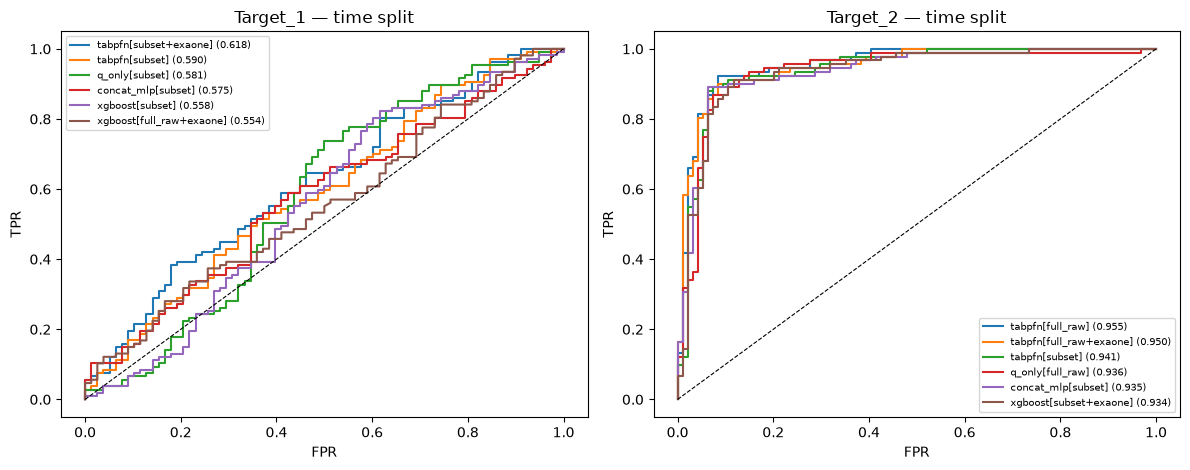

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, t in zip(axes, TARGETS):
    top = time_tab[t].sort_values(ascending=False).index[:6]
    for v in top:
        k = f"time|{t}|{v}"
        if k in preds:
            fpr, tpr, _ = roc_curve(preds[k]["y"], preds[k]["p"])
            ax.plot(fpr, tpr, label=f"{v} ({roc_auc_score(preds[k]['y'], preds[k]['p']):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set(title=f"{t} — time split", xlabel="FPR", ylabel="TPR")
    ax.legend(fontsize=7)
plt.tight_layout()